<a href="https://colab.research.google.com/github/ferresmanuela/credit-default-ml/blob/main/proyecto_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de Default en Tarjetas de Crédito
**Autor:** Pablo Ferres — Data Science II: Machine Learning (Coderhouse)

## 1. Formulación del problema

**Contexto de negocio:** Una entidad emisora de tarjetas de crédito necesita anticipar qué clientes no pagarán su resumen el mes siguiente, para tomar acciones preventivas (reducción de límite, contacto de cobranza, refinanciación).

**Tarea:** Clasificación binaria supervisada.

**Variable objetivo:** `default` → 1 = el cliente incurre en default el mes siguiente; 0 = paga.

**Métricas de éxito:**
- **ROC AUC** (métrica principal): mide la capacidad del modelo de ordenar clientes por riesgo, independientemente del umbral.
- **Recall de la clase 1** (métrica de negocio): un falso negativo (no detectar a un moroso) tiene un costo mucho mayor que un falso positivo (revisar a un buen pagador).

**Dataset:** *Default of Credit Card Clients* (UCI Machine Learning Repository, id 350). 30.000 clientes de Taiwán, abril–septiembre 2005.

**Hipótesis:**
1. El historial reciente de atrasos (`PAY_0`) es el predictor más fuerte de default.
2. Los clientes con alta utilización del límite (deuda / límite) tienen mayor probabilidad de default.
3. Los clientes que pagan una proporción baja de lo facturado presentan mayor riesgo.
4. Las variables demográficas (sexo, estado civil, educación) tienen menor poder predictivo que las de comportamiento de pago.


In [1]:
!pip install ucimlrepo xgboost shap -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from ucimlrepo import fetch_ucirepo

# Semilla fija para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 30)
plt.style.use('seaborn-v0_8-whitegrid')

## 2. Carga de datos
Se descargan los datos directamente desde el repositorio de UCI con `ucimlrepo`, lo que garantiza que cualquier persona pueda reproducir el notebook sin descargar archivos manualmente.

In [4]:
credit = fetch_ucirepo(id=350)
X_raw = credit.data.features.copy()
y_raw = credit.data.targets.copy()

print("Columnas originales:", X_raw.columns.tolist()[:5], "...")
print("Shape X:", X_raw.shape, "| Shape y:", y_raw.shape)

Columnas originales: ['X1', 'X2', 'X3', 'X4', 'X5'] ...
Shape X: (30000, 23) | Shape y: (30000, 1)


In [5]:
# Nombres según la documentación oficial de UCI
cols = ['LIMIT_BAL','SEX','EDUCATION','MARRIAGE','AGE',
        'PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6',
        'BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6',
        'PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6']

X_raw.columns = cols
y_raw.columns = ['default']
df = pd.concat([X_raw, y_raw], axis=1)

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_0      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Diccionario de variables
| Variable | Descripción |
|---|---|
| LIMIT_BAL | Límite de crédito (NT$), incluye crédito familiar |
| SEX | 1 = masculino, 2 = femenino |
| EDUCATION | 1 = posgrado, 2 = universitario, 3 = secundario, 4 = otros |
| MARRIAGE | 1 = casado, 2 = soltero, 3 = otros |
| AGE | Edad en años |
| PAY_0, PAY_2…PAY_6 | Estado de pago sep→abr: -1 = pagó a tiempo, 1..9 = meses de atraso |
| BILL_AMT1…6 | Monto del resumen sep→abr (NT$) |
| PAY_AMT1…6 | Monto pagado sep→abr (NT$) |
| default | 1 = default el mes siguiente, 0 = no |

*Nota: la numeración de PAY salta de 0 a 2 en el dataset original (no existe PAY_1).*

## 3. Análisis Exploratorio de Datos (EDA)
### 3.1 Calidad de datos: nulos, duplicados y tipos

In [6]:
print("Nulos por columna:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("\nTipos de datos:\n", df.dtypes.value_counts())
df.describe().T

Nulos por columna: 0
Filas duplicadas: 35

Tipos de datos:
 int64    24
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


**Observaciones sobre calidad de datos:**
- No hay valores nulos en ninguna variable.
- Se detectan **35 filas duplicadas** (0,1%). Dado que el dataset no incluye el ID del cliente, no es posible confirmar si son registros repetidos o clientes con valores idénticos; se eliminarán para evitar que una misma observación quede en train y test.
- **EDUCATION** presenta valores 0, 5 y 6, y **MARRIAGE** el valor 0, no contemplados en la documentación.
- Las variables **PAY_x** toman valores entre -2 y 8, aunque la documentación solo describe -1 y 1-9. Siguiendo la interpretación habitual en la literatura sobre este dataset: -2 = sin consumo en el período, -1 = pago total, 0 = pago mínimo (uso de crédito rotativo), 1-8 = meses de atraso.
- **LIMIT_BAL** presenta asimetría positiva (media 167.484 > mediana 140.000), con un máximo de 1.000.000.
- La edad de los clientes va de 21 a 79 años (mediana 34).
- **Variable objetivo:** el 22,1% de los clientes incurre en default. Existe un desbalance moderado que se abordará con split estratificado y ponderación de clases.
- **BILL_AMT** presenta valores negativos (saldos a favor del cliente por pagos en exceso); se consideran válidos y se conservan.
- El máximo de BILL_AMT3 (1.664.089) supera el máximo de LIMIT_BAL (1.000.000): existen clientes **excedidos de su límite**, lo que motiva crear un ratio de utilización.
- **PAY_AMT** muestra fuerte asimetría (media ≈ 2,5 veces la mediana, máximos de hasta 1,68 millones). Se evaluará una transformación logarítmica para los modelos lineales.
- La deuda promedio crece de abril (BILL_AMT6: 38.872) a septiembre (BILL_AMT1: 51.223), lo que sugiere una **tendencia de endeudamiento creciente** en la cartera.

### 3.2 Distribución de la variable objetivo

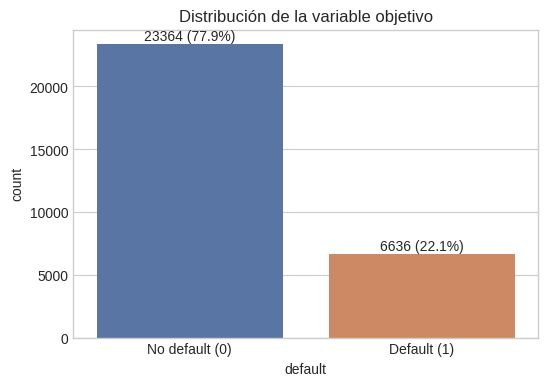

In [7]:
conteo = df['default'].value_counts()
prop = df['default'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(x='default', data=df, ax=ax, palette=['#4C72B0','#DD8452'])
for i, v in enumerate(conteo):
    ax.text(i, v + 300, f"{v} ({prop[i]:.1f}%)", ha='center')
ax.set_title('Distribución de la variable objetivo')
ax.set_xticklabels(['No default (0)', 'Default (1)'])
plt.show()

### 3.3 Variables categóricas: valores no documentados
Según la documentación, EDUCATION toma valores 1-4 y MARRIAGE 1-3. Verificamos si aparecen otros.

In [8]:
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f"\n{col}:\n", df[col].value_counts().sort_index())

print("\nValores únicos de PAY_0:", sorted(df['PAY_0'].unique()))


SEX:
 SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
 EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
 MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

Valores únicos de PAY_0: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


**Observaciones sobre variables categóricas:**
- **SEX:** la cartera está compuesta mayoritariamente por mujeres (60,4%) frente a hombres (39,6%).
- **EDUCATION:** 345 registros (1,2%) presentan valores no documentados (0, 5 y 6). Al no poder determinar su significado y ser una proporción mínima, se agruparán en la categoría 4 ("otros").
- **MARRIAGE:** 54 registros presentan el valor 0, no documentado. Se agruparán en la categoría 3 ("otros").
- **PAY_x:** toman valores de -2 a 8; no se observan registros con 9 meses de atraso.

### 3.4 Tasa de default por variable categórica

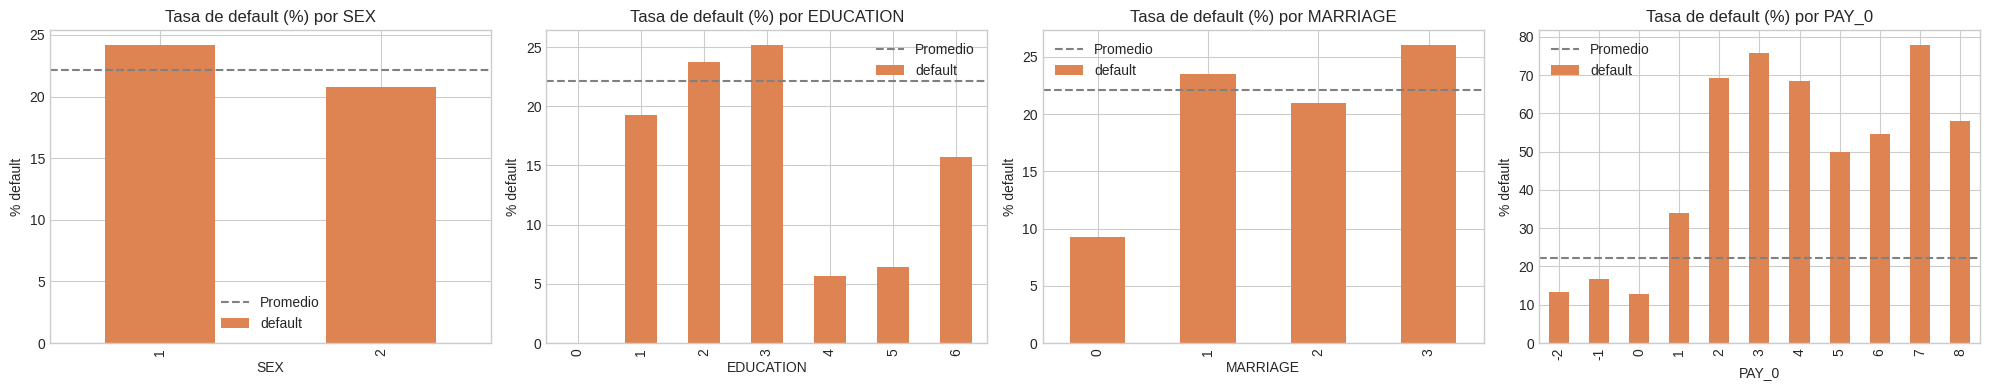

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20,4))
for ax, col in zip(axes, ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0']):
    tasa = df.groupby(col)['default'].mean() * 100
    tasa.plot(kind='bar', ax=ax, color='#DD8452')
    ax.set_title(f'Tasa de default (%) por {col}')
    ax.set_ylabel('% default')
    ax.axhline(df['default'].mean()*100, color='gray', ls='--', label='Promedio')
    ax.legend()
plt.tight_layout()
plt.show()

### 3.5 Distribución de variables numéricas según default

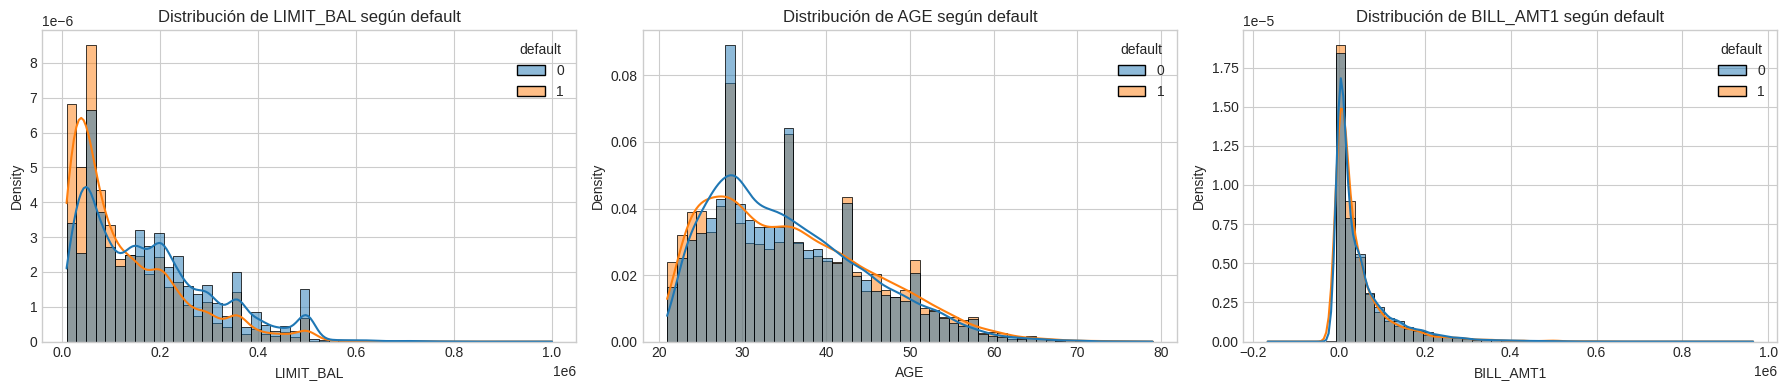

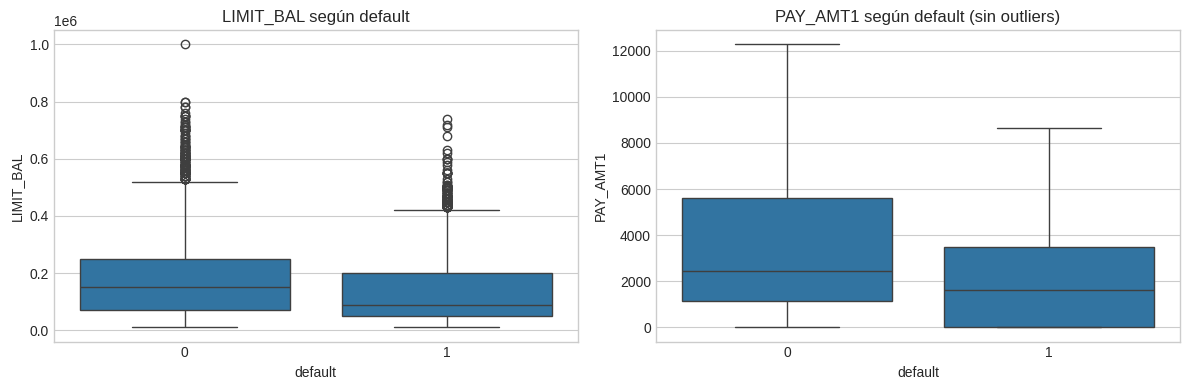

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))
for ax, col in zip(axes, ['LIMIT_BAL', 'AGE', 'BILL_AMT1']):
    sns.histplot(data=df, x=col, hue='default', bins=50, kde=True,
                 stat='density', common_norm=False, ax=ax)
    ax.set_title(f'Distribución de {col} según default')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(x='default', y='LIMIT_BAL', data=df, ax=axes[0])
axes[0].set_title('LIMIT_BAL según default')
sns.boxplot(x='default', y='PAY_AMT1', data=df, ax=axes[1], showfliers=False)
axes[1].set_title('PAY_AMT1 según default (sin outliers)')
plt.tight_layout()
plt.show()

### 3.6 Correlaciones

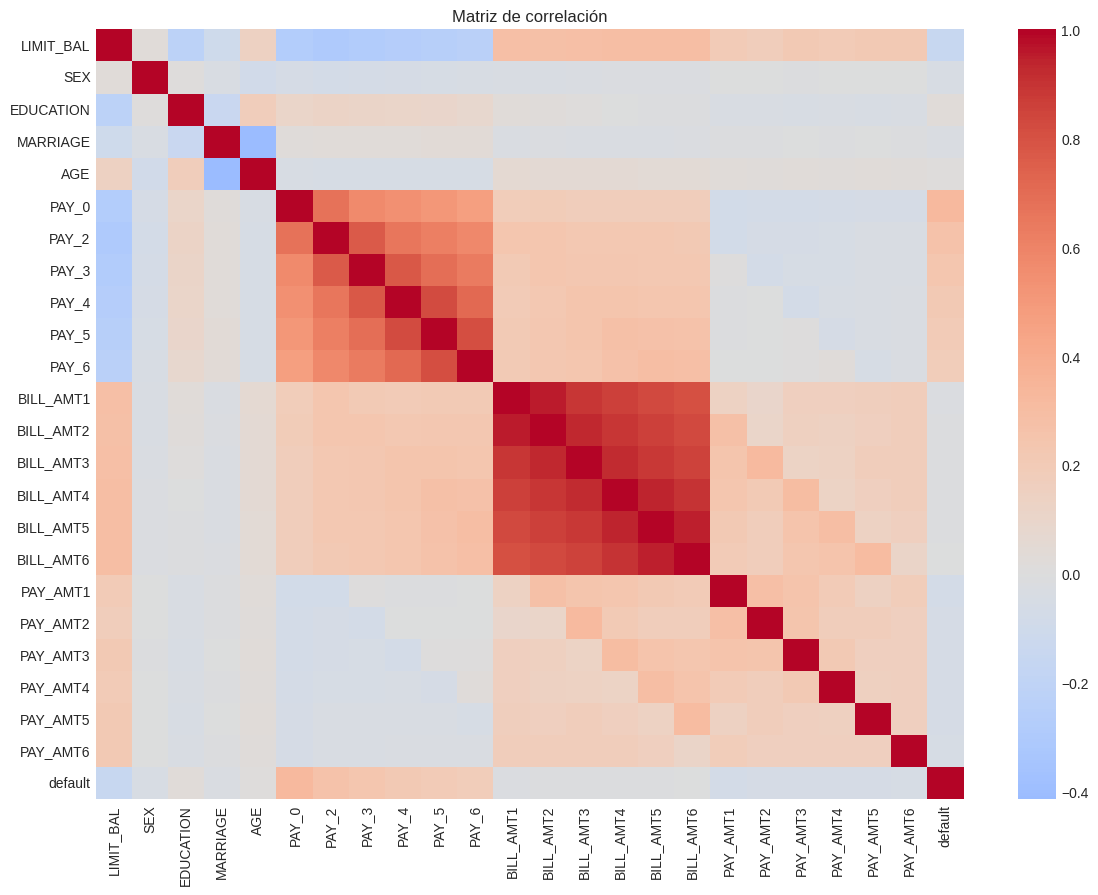

Correlación de cada variable con el target:

PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
EDUCATION    0.028
AGE          0.014
BILL_AMT6   -0.005
BILL_AMT5   -0.007
BILL_AMT4   -0.010
BILL_AMT3   -0.014
BILL_AMT2   -0.014
BILL_AMT1   -0.020
MARRIAGE    -0.024
SEX         -0.040
PAY_AMT6    -0.053
PAY_AMT5    -0.055
PAY_AMT3    -0.056
PAY_AMT4    -0.057
PAY_AMT2    -0.059
PAY_AMT1    -0.073
LIMIT_BAL   -0.154
Name: default, dtype: float64


In [11]:
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Matriz de correlación')
plt.show()

print("Correlación de cada variable con el target:\n")
print(df.corr()['default'].drop('default').sort_values(ascending=False).round(3))

**Observaciones sobre correlaciones:**
- **PAY_0** (estado de pago del último mes) es la variable más correlacionada con el default (r = 0,325), y la correlación decrece con la antigüedad del mes (PAY_6: r = 0,187). Esto respalda preliminarmente la **Hipótesis 1**: el comportamiento de pago reciente es el principal predictor.
- **LIMIT_BAL** presenta correlación negativa (r = -0,154): clientes con mayor límite de crédito, presumiblemente mejor evaluados por la entidad, incumplen menos.
- Los montos facturados (**BILL_AMT**) prácticamente no correlacionan con el target (|r| ≤ 0,02). El monto absoluto de deuda no es informativo por sí solo; la **Hipótesis 2** plantea que sí lo será la deuda **relativa al límite**, lo que se evaluará mediante un ratio de utilización.
- Los montos pagados (**PAY_AMT**) muestran correlación negativa débil (r entre -0,05 y -0,07), en línea con la **Hipótesis 3**, que se evaluará mediante un ratio de pago sobre lo facturado.
- Las variables demográficas (**SEX, EDUCATION, MARRIAGE, AGE**) presentan correlaciones muy bajas (|r| < 0,05), respaldando preliminarmente la **Hipótesis 4**.
- El heatmap evidencia **alta correlación entre las BILL_AMT** de distintos meses (multicolinealidad), lo que refuerza la conveniencia de resumirlas en variables derivadas.
- *Nota:* el coeficiente de Pearson solo captura relaciones lineales; los modelos basados en árboles podrán detectar relaciones no lineales.

### 3.7 Outliers

In [12]:
num_cols = ['LIMIT_BAL'] + [f'BILL_AMT{i}' for i in range(1,7)] + [f'PAY_AMT{i}' for i in range(1,7)]

outliers = {}
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers[col] = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()

print(pd.Series(outliers, name='Outliers (IQR)').sort_values(ascending=False))
print("\nBILL_AMT negativos (saldo a favor):", (df[[f'BILL_AMT{i}' for i in range(1,7)]] < 0).sum().sum())

PAY_AMT4     2994
PAY_AMT6     2958
PAY_AMT5     2945
PAY_AMT1     2745
BILL_AMT5    2725
PAY_AMT2     2714
BILL_AMT6    2693
BILL_AMT4    2622
PAY_AMT3     2598
BILL_AMT3    2469
BILL_AMT1    2400
BILL_AMT2    2395
LIMIT_BAL     167
Name: Outliers (IQR), dtype: int64

BILL_AMT negativos (saldo a favor): 3932


**Observaciones sobre outliers:**
- Según el criterio IQR, las variables de montos (**BILL_AMT** y **PAY_AMT**) presentan entre 2.400 y 3.000 outliers cada una (8-10% de los registros). **LIMIT_BAL** presenta solo 167 (0,6%).
- Estos valores **no se consideran errores**, sino la cola larga propia de los datos financieros (clientes con deudas o pagos elevados). Eliminarlos implicaría perder una proporción significativa de la muestra y, posiblemente, información relevante para el modelo.
- **Decisión:** se conservan los outliers. Para los modelos lineales se aplicará una transformación logarítmica que reduzca su influencia; los modelos basados en árboles (Random Forest, XGBoost) son robustos a valores extremos por construcción.
- Se registran 3.932 valores negativos en BILL_AMT (sumando los 6 meses), correspondientes a saldos a favor del cliente; se conservan.

### 3.8 Conclusiones del EDA
1. **Calidad de datos:** el dataset no presenta nulos. Se eliminarán 35 duplicados y se agruparán los valores no documentados de EDUCATION (0, 5, 6 → 4) y MARRIAGE (0 → 3).
2. **Desbalance:** el 22,1% de los clientes incurre en default. Se utilizará split estratificado, validación cruzada estratificada y ponderación de clases.
3. **Comportamiento de pago:** el historial de pagos (PAY_x), especialmente el más reciente, es la señal más fuerte disponible.
4. **Montos absolutos poco informativos:** los montos facturados no correlacionan con el default, lo que motiva crear **variables relativas** (utilización del límite, proporción pagada sobre lo facturado) y variables de **tendencia**.
5. **Variables demográficas:** poder predictivo bajo a priori.
6. **Outliers:** se conservan; se tratarán con transformación logarítmica en modelos lineales.
7. **Multicolinealidad:** alta correlación entre las BILL_AMT, que se mitigará con variables resumen.